# Loan benchmark: results

The baseline agent (handed the SOP and the policy) against the AIP agent (runs the procedure), on the thirty applications.

This notebook reads the run files under `bench/results/` and scores them with `bench/score.py`, the same scorer the command line uses. Results are not in git, so it shows whatever runs are on this machine. To open it: `uv run --with pandas --with matplotlib --with jupyter jupyter lab analysis.ipynb`.

Four parts: the results matrix and the baseline against AIP at each effort, the two messages, tokens and cost, and what more thinking changes.

In [1]:
import json, pathlib, re, sys
import pandas as pd
from IPython.display import display, HTML, Markdown

DEMO = pathlib.Path.cwd()
sys.path.insert(0, str(DEMO / "bench"))
import score

RESULTS = DEMO / "bench" / "results"

def latest(pattern):
    """The newest results folder matching the pattern, by name (names end in the start time)."""
    return sorted(RESULTS.glob(pattern))[-1].name

# Which runs to show: (effort, arm, results folder, cell inside it).
# The low-effort AIP cell is the rerun made after the procedure took the application as a file.
RUNS = [
    ("low", "Baseline", "tiers-haiku-low-20261119-054243", "baseline-haiku-low"),
    ("low", "AIP",      "tiers-aip-mcp-20261119-055851",   "aip-mcp-haiku-low"),
    ("max", "Baseline", latest("tiers-haiku-max-*"),       "baseline-haiku-max"),
    ("max", "AIP",      latest("tiers-haiku-max-*"),       "aip-mcp-haiku-max"),
]
EXPECTED = json.loads((DEMO / "expected.json").read_text())
TIERS = ["easy", "medium", "hard"]
pd.set_option("display.max_colwidth", None)

In [2]:
def load():
    rows = []
    for effort, arm, folder, cell in RUNS:
        for path in sorted((RESULTS / folder / "runs" / cell).glob("*.json")):
            if not re.search(r"\.r\d+\.json$", path.name):
                continue
            record = json.loads(path.read_text())
            row = score.score(record, EXPECTED)
            answer = (record.get("claude") or {}).get("structured_output") or {}
            row.update(effort=effort, arm=arm, model=record["model"],
                       cost_exact=(record.get("claude") or {}).get("total_cost_usd") or 0.0,   # score.py rounds to 4 places
                       customer_text=answer.get("customer_message", ""), officer_text=answer.get("officer_message", ""))
            rows.append(row)
    return pd.DataFrame(rows)

runs = load()
runs["decided"] = (runs[["outcome", "failed_rules", "missing"]].sum(axis=1) == 3).astype(int)
COLUMNS = [(e, a) for e, a, _, _ in RUNS if ((runs.effort == e) & (runs.arm == a)).any()]
print("Runs loaded, all on", ", ".join(sorted(runs.model.unique())))
display(runs.groupby(["effort", "arm"]).agg(runs=("application", "size"), applications=("application", "nunique"),
                                             repeats=("repeat", "nunique"), answered=("answered", "sum")))

Runs loaded, all on haiku


runs  applications  repeats  answered
effort arm                                            
low    AIP        150            30        5       150
       Baseline   150            30        5       150
max    AIP         60            30        2        60
       Baseline    60            30        2        60

## 1. The results matrix

One column per arm and effort. A run's outcome, rule list and missing list are each right or wrong. "Every repeat agreed" counts the applications where all repeats of that arm gave the same outcome and the same rule list.

In [3]:
def share(part):
    return f"{int(part.sum())}/{len(part)} ({part.mean():.0%})" if len(part) else "-"

def stable(part):
    answers = part.groupby("application").apply(lambda g: len(set(zip(g.got, g.got_failed_rules))), include_groups=False)
    return f"{int((answers == 1).sum())} of {len(answers)}"

def matrix():
    table = {}
    for effort, arm in COLUMNS:
        part = runs[(runs.effort == effort) & (runs.arm == arm)]
        column = {"Outcome correct": share(part.outcome)}
        for tier in TIERS:
            column[f"   {tier}"] = share(part[part.difficulty == tier].outcome)
        column.update({
            "Rules list correct": share(part.failed_rules),
            "Missing list correct": share(part.missing),
            "Every repeat agreed (applications)": stable(part),
            "Customer message passes rubric": share(part.customer_message),
            "Officer message passes rubric": share(part.officer_message),
            "Tokens per run": f"{part.tokens_total.mean():,.0f}",
            "   of which thinking": f"{part.tokens_thinking.mean():,.0f}",
            "Cost per run": f"${part.cost_usd.mean():.4f}",
            "Turns per run": f"{part.turns.mean():.1f}",
            "Seconds per run, mean": f"{part.seconds.mean():.1f}",
            "Seconds per run, max": f"{part.seconds.max():.1f}",
        })
        table[(f"Haiku {effort}", arm)] = column
    return pd.DataFrame(table)

matrix()

Haiku low                  \
                                          Baseline             AIP   
Outcome correct                      141/150 (94%)  150/150 (100%)   
   easy                                48/50 (96%)    50/50 (100%)   
   medium                             50/50 (100%)    50/50 (100%)   
   hard                                43/50 (86%)    50/50 (100%)   
Rules list correct                   137/150 (91%)  150/150 (100%)   
Missing list correct                150/150 (100%)  150/150 (100%)   
Every repeat agreed (applications)        25 of 30        30 of 30   
Customer message passes rubric       124/150 (83%)   131/150 (87%)   
Officer message passes rubric         59/150 (39%)    98/150 (65%)   
Tokens per run                               9,192          33,107   
   of which thinking                           809             751   
Cost per run                               $0.0011         $0.0024   
Turns per run                                  5.0             6.8   
Seconds per run, mean                          8.1            13.7   
Seconds per run, max                          17.2            77.9   

                                       Haiku max                
                                        Baseline           AIP  
Outcome correct                      58/60 (97%)  60/60 (100%)  
   easy                              18/20 (90%)  20/20 (100%)  
   medium                           20/20 (100%)  20/20 (100%)  
   hard                             20/20 (100%)  20/20 (100%)  
Rules list correct                   56/60 (93%)  60/60 (100%)  
Missing list correct                60/60 (100%)  60/60 (100%)  
Every repeat agreed (applications)      30 of 30      30 of 30  
Customer message passes rubric       51/60 (85%)  60/60 (100%)  
Officer message passes rubric        55/60 (92%)   59/60 (98%)  
Tokens per run                            70,336        76,903  
   of which thinking                      35,186        26,413  
Cost per run                             $0.0208       $0.0181  
Turns per run                                5.7           5.1  
Seconds per run, mean                      142.6         106.3  
Seconds per run, max                       335.5         232.5

### Where each arm went wrong

Every application an arm got wrong at least once, with the answers it gave across its repeats. The outcome is followed by the rule list in brackets.

In [4]:
def wrong_answers():
    rows = []
    for (effort, arm, application), part in runs.groupby(["effort", "arm", "application"]):
        if part.decided.all():
            continue
        answers = (part.got + " [" + part.got_failed_rules + "]").value_counts()
        want = EXPECTED[application]
        rows.append({"effort": effort, "arm": arm, "application": application, "tier": want["difficulty"],
                     "expected": f"{want['outcome']} [{' '.join(want['failed_rules'])}]",
                     "answers given": ";  ".join(f"{a} x{n}" for a, n in answers.items())})
    return pd.DataFrame(rows).set_index(["effort", "arm", "application"]) if rows else "No arm got any application wrong."

wrong_answers()

tier       expected  \
effort arm      application                        
low    Baseline APP-2001     easy     approve []   
                APP-2004     easy  escalate [J1]   
                APP-2005     easy  escalate [J3]   
                APP-2201     hard     approve []   
                APP-2209     hard  escalate [J1]   
                APP-2210     hard     approve []   
max    Baseline APP-2001     easy     approve []   
                APP-2005     easy  escalate [J3]   

                                                      answers given  
effort arm      application                                          
low    Baseline APP-2001           approve [] x3;  escalate [J3] x2  
                APP-2004     escalate [J1] x4;  escalate [J1 J2] x1  
                APP-2005     escalate [J3] x4;  escalate [J3 J5] x1  
                APP-2201           approve [] x3;  escalate [J3] x2  
                APP-2209     escalate [J1] x3;  escalate [J1 J2] x2  
                APP-2210                           escalate [J3] x5  
max    Baseline APP-2001                           escalate [J3] x2  
                APP-2005                        escalate [J3 J5] x2

### Baseline against AIP, at each effort

The same comparison as a short table for each effort, first over all thirty applications, then for the easy, medium and hard tiers apart. "Change" is AIP against the baseline: in percentage points for the three correctness rows, in percent for the rest (as a multiple when it more than doubles).

In [5]:
def facts(part):
    return {"Outcome correct": ("rate", part.outcome), "Rules list correct": ("rate", part.failed_rules),
            "Missing list correct": ("rate", part.missing),
            "Thinking tokens per run": ("count", part.tokens_thinking.mean()),
            "All tokens per run": ("count", part.tokens_total.mean()),
            "Cost per run": ("money", part.cost_exact.mean()),
            "Seconds per run": ("seconds", part.seconds.mean())}

def shown(kind, value):
    if kind == "rate":
        return share(value)
    return {"count": f"{value:,.0f}", "money": f"${value:.4f}", "seconds": f"{value:.1f}"}[kind]

def change(kind, first, second):
    if kind == "rate":
        points = (second.mean() - first.mean()) * 100
        return "same" if abs(points) < 0.5 else f"{points:+.0f} points"
    percent = (second / first - 1) * 100
    if percent >= 100:                      # a large rise reads better as a multiple
        return f"up {second / first:.1f}x"
    return "same" if abs(percent) < 0.5 else f"{'up' if percent > 0 else 'down'} {abs(percent):.0f}%"

def contrast(first, second, names):
    """Two sets of runs side by side, with the change from the first to the second."""
    a, b = facts(first), facts(second)
    return pd.DataFrame({names[0]: {k: shown(*a[k]) for k in a}, names[1]: {k: shown(*b[k]) for k in b},
                         "Change": {k: change(a[k][0], a[k][1], b[k][1]) for k in a}})

def pick(effort, arm, tier=None):
    part = runs[(runs.effort == effort) & (runs.arm == arm)]
    return part if tier is None else part[part.difficulty == tier]

for effort in dict.fromkeys(e for e, _ in COLUMNS):
    display(Markdown(f"**Haiku {effort}, all thirty applications**"))
    display(contrast(pick(effort, "Baseline"), pick(effort, "AIP"), ["Baseline", "AIP"]))
    display(Markdown(f"**Haiku {effort}, by tier**"))
    display(pd.concat({tier: contrast(pick(effort, "Baseline", tier), pick(effort, "AIP", tier), ["Baseline", "AIP"])
                       for tier in TIERS}, axis=1))

**Haiku low, all thirty applications**

,Baseline,AIP,Change
Outcome correct,141/150 (94%),150/150 (100%),+6 points
Rules list correct,137/150 (91%),150/150 (100%),+9 points
Missing list correct,150/150 (100%),150/150 (100%),same
Thinking tokens per run,809,751,down 7%
All tokens per run,"9,192","33,107",up 3.6x
Cost per run,$0.0011,$0.0024,up 2.3x
Seconds per run,8.1,13.7,up 70%


**Haiku low, by tier**

easy                                 medium  \
                             Baseline           AIP     Change      Baseline   
Outcome correct           48/50 (96%)  50/50 (100%)  +4 points  50/50 (100%)   
Rules list correct        46/50 (92%)  50/50 (100%)  +8 points  50/50 (100%)   
Missing list correct     50/50 (100%)  50/50 (100%)       same  50/50 (100%)   
Thinking tokens per run           695           667    down 4%           696   
All tokens per run              9,277        31,897    up 3.4x         8,944   
Cost per run                  $0.0011       $0.0024    up 2.2x       $0.0010   
Seconds per run                   7.5          12.4     up 64%           7.2   

                                                         hard                \
                                  AIP    Change      Baseline           AIP   
Outcome correct          50/50 (100%)      same   43/50 (86%)  50/50 (100%)   
Rules list correct       50/50 (100%)      same   41/50 (82%)  50/50 (100%)   
Missing list correct     50/50 (100%)      same  50/50 (100%)  50/50 (100%)   
Thinking tokens per run           593  down 15%         1,035           994   
All tokens per run             32,772   up 3.7x         9,354        34,653   
Cost per run                  $0.0023   up 2.4x       $0.0012       $0.0027   
Seconds per run                  13.9    up 92%           9.4          14.7   

                                     
                             Change  
Outcome correct          +14 points  
Rules list correct       +18 points  
Missing list correct           same  
Thinking tokens per run     down 4%  
All tokens per run          up 3.7x  
Cost per run                up 2.3x  
Seconds per run              up 57%

**Haiku max, all thirty applications**

,Baseline,AIP,Change
Outcome correct,58/60 (97%),60/60 (100%),+3 points
Rules list correct,56/60 (93%),60/60 (100%),+7 points
Missing list correct,60/60 (100%),60/60 (100%),same
Thinking tokens per run,"35,186","26,413",down 25%
All tokens per run,"70,336","76,903",up 9%
Cost per run,$0.0208,$0.0181,down 13%
Seconds per run,142.6,106.3,down 25%


**Haiku max, by tier**

easy                                  medium  \
                             Baseline           AIP      Change      Baseline   
Outcome correct           18/20 (90%)  20/20 (100%)  +10 points  20/20 (100%)   
Rules list correct        16/20 (80%)  20/20 (100%)  +20 points  20/20 (100%)   
Missing list correct     20/20 (100%)  20/20 (100%)        same  20/20 (100%)   
Thinking tokens per run        33,340        22,523    down 32%        30,688   
All tokens per run             58,799        68,683      up 17%        60,819   
Cost per run                  $0.0190       $0.0157    down 18%       $0.0184   
Seconds per run                 134.9          92.2    down 32%         124.1   

                                                         hard                \
                                  AIP    Change      Baseline           AIP   
Outcome correct          20/20 (100%)      same  20/20 (100%)  20/20 (100%)   
Rules list correct       20/20 (100%)      same  20/20 (100%)  20/20 (100%)   
Missing list correct     20/20 (100%)      same  20/20 (100%)  20/20 (100%)   
Thinking tokens per run        27,382  down 11%        41,532        29,333   
All tokens per run             80,927    up 33%        91,389        81,099   
Cost per run                  $0.0187     up 2%       $0.0249       $0.0198   
Seconds per run                 109.1  down 12%         168.9         117.6   

                                   
                           Change  
Outcome correct              same  
Rules list correct           same  
Missing list correct         same  
Thinking tokens per run  down 29%  
All tokens per run       down 11%  
Cost per run             down 20%  
Seconds per run          down 30%

### The same comparison as a picture

One row of charts for each effort. In each chart the four groups are all thirty applications and then the easy, medium and hard tiers, with the baseline and AIP side by side. Every chart has its own scale starting at zero, and lower is better in all four: wrong outcomes, thinking tokens, cost and time.

The first chart shows wrong outcomes, not correct ones, because the difference between 86% and 100% correct is hard to see on a bar and the difference between 14% wrong and none is not.

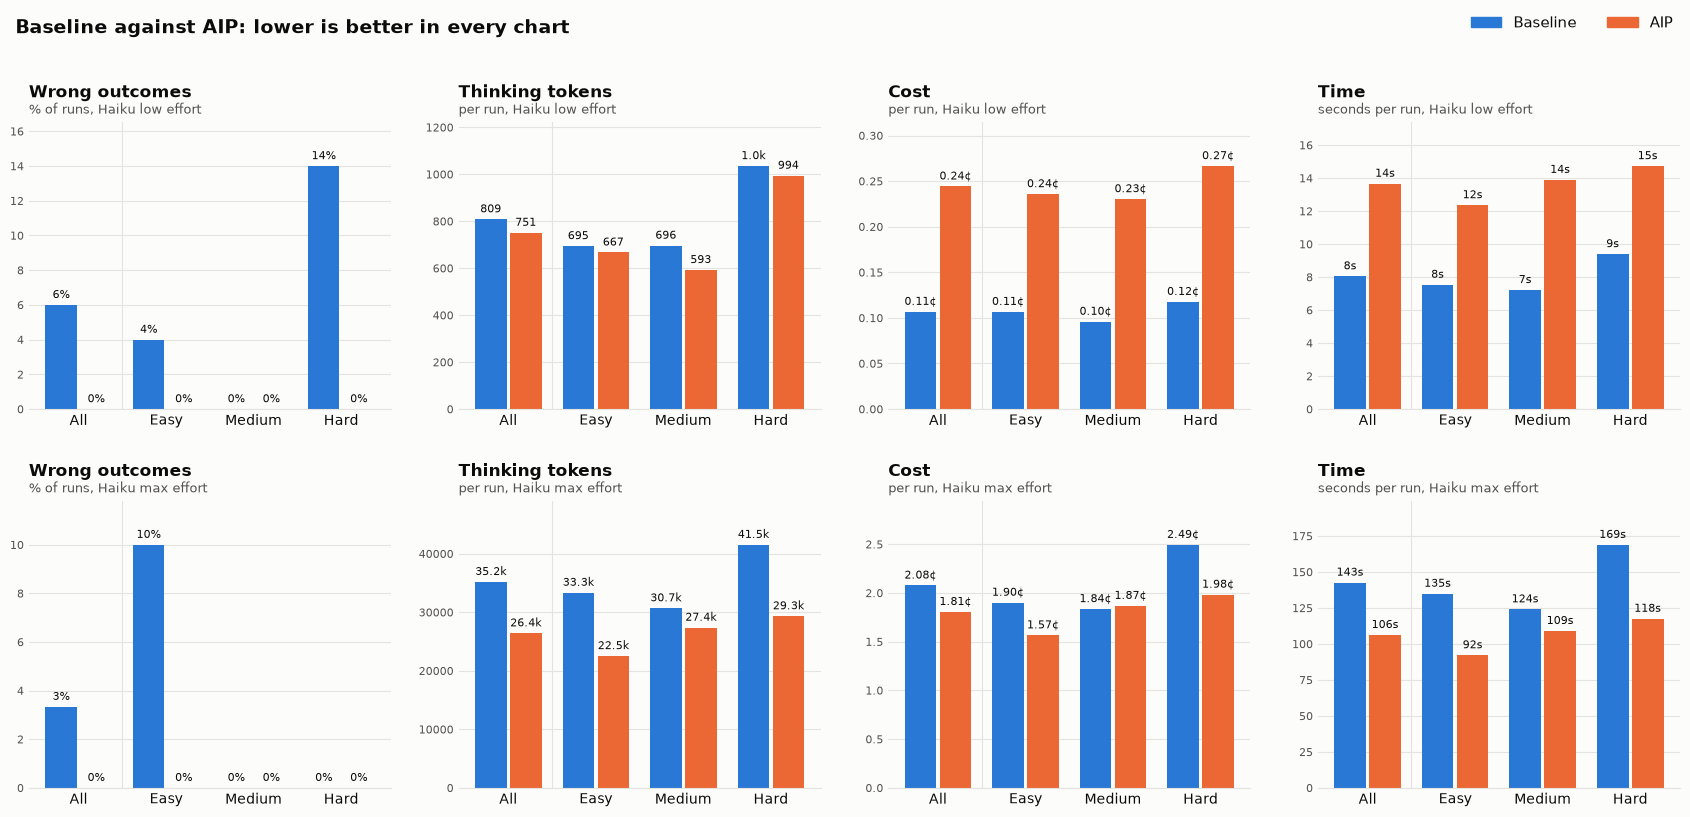

In [6]:
import matplotlib.pyplot as plt

INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
ARM_COLOR = {"Baseline": "#2a78d6", "AIP": "#eb6834"}       # validated as a colourblind-safe pair
PANELS = [("Wrong outcomes", "% of runs", lambda part: (1 - part.outcome.mean()) * 100, lambda v: f"{v:.0f}%"),
          ("Thinking tokens", "per run", lambda part: part.tokens_thinking.mean(), lambda v: f"{v / 1000:.1f}k" if v >= 1000 else f"{v:.0f}"),
          ("Cost", "per run", lambda part: part.cost_exact.mean() * 100, lambda v: f"{v:.2f}¢"),
          ("Time", "seconds per run", lambda part: part.seconds.mean(), lambda v: f"{v:.0f}s")]
SCOPES = [("All", None)] + [(tier.capitalize(), tier) for tier in TIERS]

def comparison_chart():
    efforts = list(dict.fromkeys(e for e, _ in COLUMNS))
    fig, axes = plt.subplots(len(efforts), len(PANELS), figsize=(17, 4.1 * len(efforts)), facecolor=SURFACE, squeeze=False)
    width = 0.36
    for row, effort in enumerate(efforts):
        for col, (title, unit, measure, label) in enumerate(PANELS):
            ax = axes[row][col]
            ax.set_facecolor(SURFACE)
            top = 0
            for offset, arm in ((-width / 2 - 0.02, "Baseline"), (width / 2 + 0.02, "AIP")):
                values = [measure(pick(effort, arm, tier)) for _, tier in SCOPES]
                top = max(top, *values)
                bars = ax.bar([x + offset for x in range(len(SCOPES))], values, width, color=ARM_COLOR[arm], label=arm)
                for bar, value in zip(bars, values):
                    ax.annotate(label(value), (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 3),
                                textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK)
            ax.set_ylim(0, top * 1.18 if top else 1)
            ax.set_xticks(range(len(SCOPES)), [name for name, _ in SCOPES], color=INK, fontsize=10)
            ax.set_title(f"{title}", loc="left", fontsize=12, color=INK, fontweight="bold", pad=18)
            ax.text(0, 1.03, f"{unit}, Haiku {effort} effort", transform=ax.transAxes, fontsize=9, color=MUTED)
            ax.yaxis.grid(True, color=GRID, linewidth=0.8)
            ax.set_axisbelow(True)
            ax.tick_params(axis="y", colors=MUTED, labelsize=8, length=0)
            ax.tick_params(axis="x", length=0)
            for side in ("top", "right", "left"):
                ax.spines[side].set_visible(False)
            ax.spines["bottom"].set_color(GRID)
            ax.axvline(0.5, color=GRID, linewidth=0.8)      # sets "All" apart from the three tiers
    handles = [plt.Rectangle((0, 0), 1, 1, color=ARM_COLOR[arm]) for arm in ARM_COLOR]
    fig.legend(handles, list(ARM_COLOR), loc="upper right", ncols=2, frameon=False, fontsize=11, labelcolor=INK,
               bbox_to_anchor=(0.995, 1.0))
    fig.suptitle("Baseline against AIP: lower is better in every chart", x=0.012, ha="left", fontsize=14, color=INK, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=2.5, w_pad=2)
    return fig

figure = comparison_chart()
figure.savefig(DEMO / "bench" / "results" / "comparison.png", dpi=140, facecolor=SURFACE)
plt.show()

### Two more figures: what was right, and what it cost

The figure above mixes the two questions. These two take them one at a time, in the same layout: a block of charts for each effort, the baseline and AIP side by side, over all thirty applications and then by tier. Lower is better throughout.

**What was right.** Each of the five things a run returns, as the share of runs that got it wrong. The two message charts use the scripted rubric, which is strict and literal (part 2 below shows what it rejects), so read them as a rough guide.

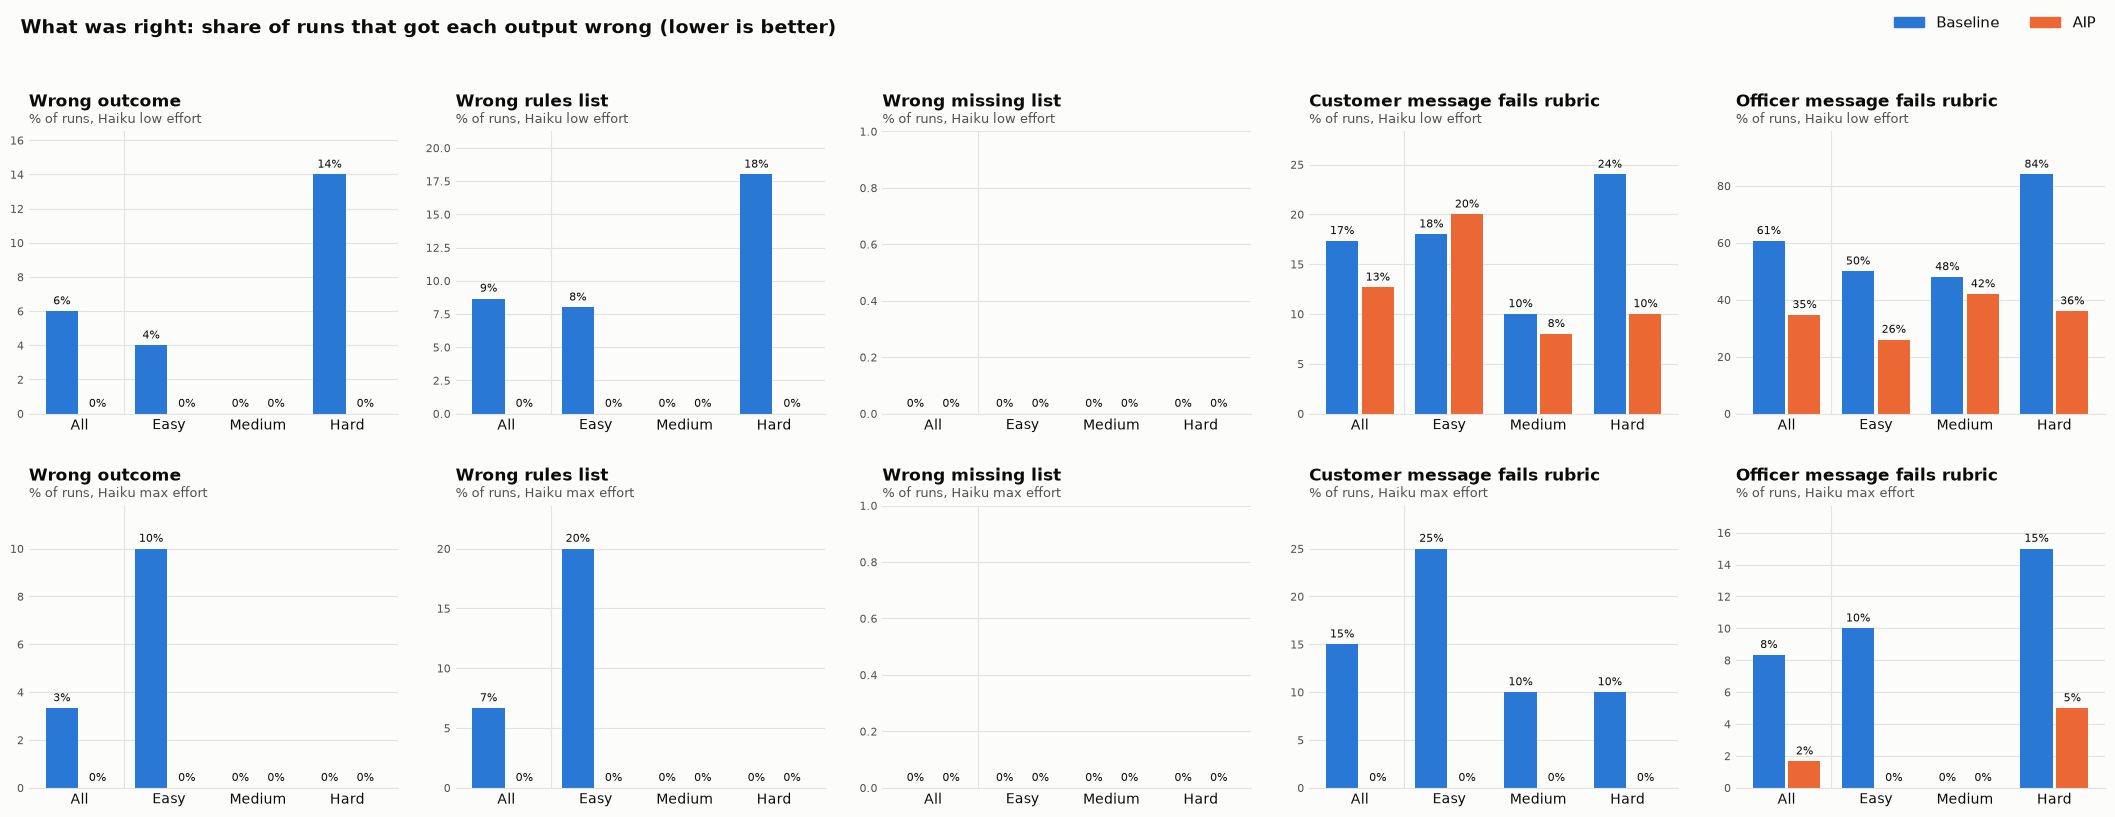

In [7]:
def bar_figure(panels, title, per_row=None, name=None):
    """A block of charts for each effort: one chart per panel, the two arms side by side in each."""
    efforts = list(dict.fromkeys(e for e, _ in COLUMNS))
    per_row = per_row or len(panels)
    block = -(-len(panels) // per_row)                       # rows of charts in one effort's block
    fig, axes = plt.subplots(block * len(efforts), per_row, figsize=(max(4.25, 23.5 / per_row) * per_row if per_row > 5 else 4.25 * per_row, 4.1 * block * len(efforts)),
                             facecolor=SURFACE, squeeze=False)
    width = 0.36
    for e, effort in enumerate(efforts):
        for i in range(block * per_row):
            ax = axes[e * block + i // per_row][i % per_row]
            if i >= len(panels):
                ax.set_visible(False)
                continue
            heading, unit, measure, label = panels[i]
            ax.set_facecolor(SURFACE)
            top = 0
            for offset, arm in ((-width / 2 - 0.02, "Baseline"), (width / 2 + 0.02, "AIP")):
                values = [measure(pick(effort, arm, tier)) for _, tier in SCOPES]
                top = max(top, *values)
                bars = ax.bar([x + offset for x in range(len(SCOPES))], values, width, color=ARM_COLOR[arm])
                for bar, value in zip(bars, values):
                    ax.annotate(label(value), (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 3),
                                textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK)
            ax.set_ylim(0, top * 1.18 if top else 1)
            ax.set_xticks(range(len(SCOPES)), [scope for scope, _ in SCOPES], color=INK, fontsize=10)
            ax.set_title(heading, loc="left", fontsize=12, color=INK, fontweight="bold", pad=18)
            ax.text(0, 1.03, f"{unit}, Haiku {effort} effort", transform=ax.transAxes, fontsize=9, color=MUTED)
            ax.yaxis.grid(True, color=GRID, linewidth=0.8)
            ax.set_axisbelow(True)
            ax.tick_params(axis="y", colors=MUTED, labelsize=8, length=0)
            ax.tick_params(axis="x", length=0)
            for side in ("top", "right", "left"):
                ax.spines[side].set_visible(False)
            ax.spines["bottom"].set_color(GRID)
            ax.axvline(0.5, color=GRID, linewidth=0.8)
    handles = [plt.Rectangle((0, 0), 1, 1, color=ARM_COLOR[arm]) for arm in ARM_COLOR]
    fig.legend(handles, list(ARM_COLOR), loc="upper right", ncols=2, frameon=False, fontsize=11, labelcolor=INK,
               bbox_to_anchor=(0.995, 1.0))
    fig.suptitle(title, x=0.012, ha="left", fontsize=14, color=INK, fontweight="bold")
    head = 1 - 0.42 / (4.1 * block * len(efforts))             # room for the title, whatever the height
    fig.tight_layout(rect=(0, 0, 1, head), h_pad=2.5, w_pad=2)
    if name:
        fig.savefig(DEMO / "bench" / "results" / name, dpi=140, facecolor=SURFACE)
    return fig

def wrong(column):
    return lambda part: (1 - part[column].mean()) * 100

percent = lambda v: f"{v:.0f}%"
CORRECTNESS = [("Wrong outcome", "% of runs", wrong("outcome"), percent),
               ("Wrong rules list", "% of runs", wrong("failed_rules"), percent),
               ("Wrong missing list", "% of runs", wrong("missing"), percent),
               ("Customer message fails rubric", "% of runs", wrong("customer_message"), percent),
               ("Officer message fails rubric", "% of runs", wrong("officer_message"), percent)]

bar_figure(CORRECTNESS, "What was right: share of runs that got each output wrong (lower is better)", name="correctness.png")
plt.show()

**What it cost.** Thinking tokens, all tokens, cost and time: the four figures that decide which arm is cheaper and faster.

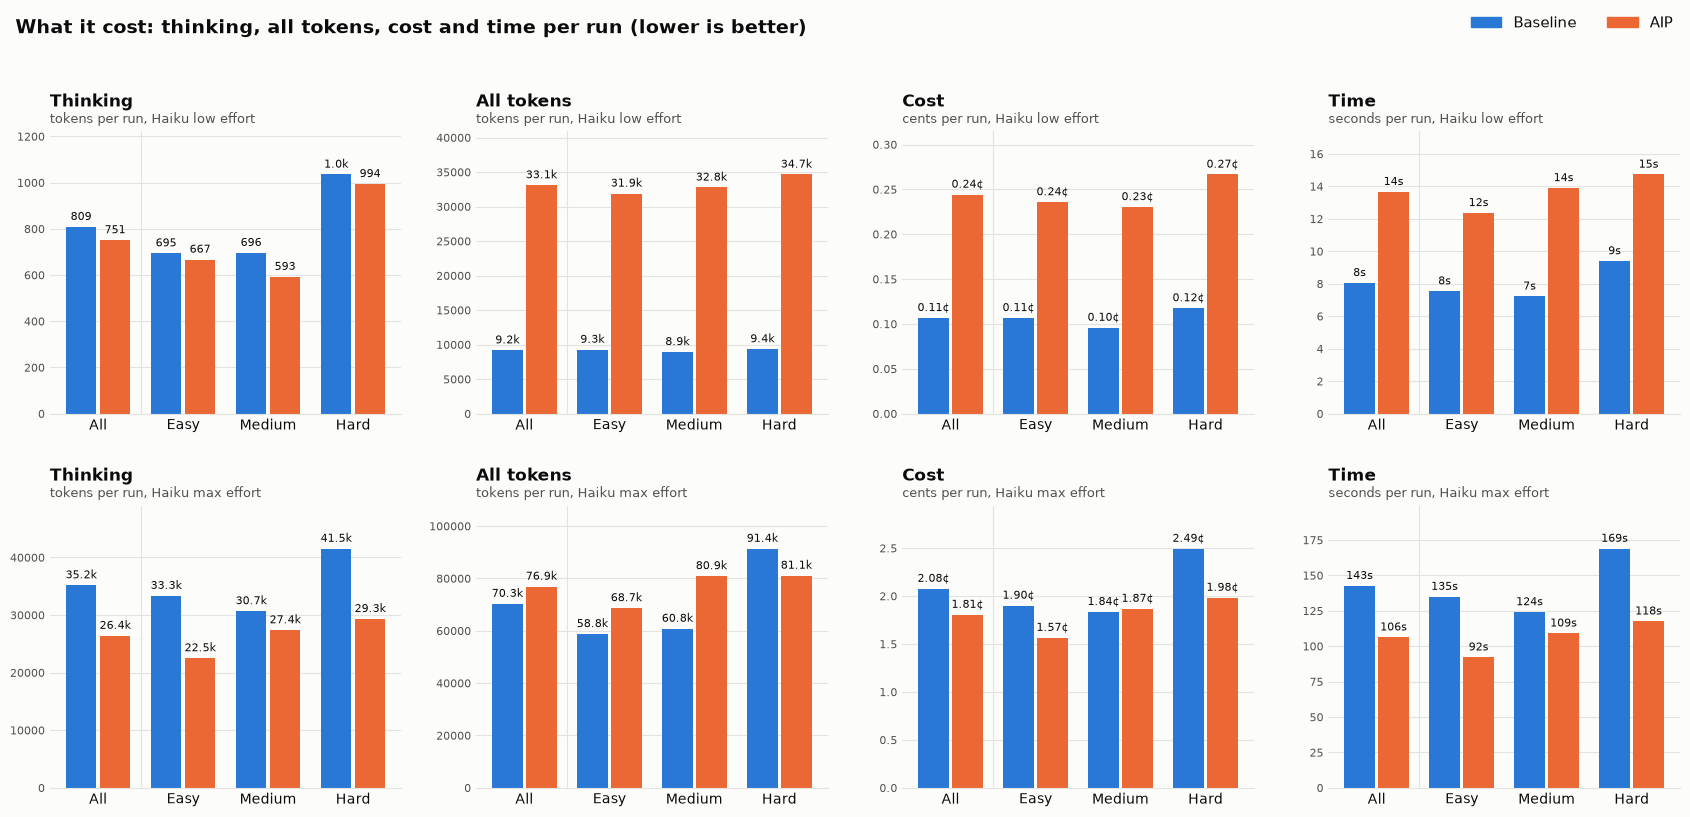

In [8]:
def thousands(v):
    return f"{v / 1000:.1f}k" if v >= 1000 else f"{v:.0f}"

SPEND = [("Input, not cached", "tokens per run", lambda part: part.tokens_input.mean(), thousands),
         ("Cache write", "tokens per run", lambda part: part.tokens_cache_write.mean(), thousands),
         ("Cache read", "tokens per run", lambda part: part.tokens_cache_read.mean(), thousands),
         ("Output, visible", "tokens per run", lambda part: (part.tokens_output - part.tokens_thinking).mean(), thousands),
         ("Thinking", "tokens per run", lambda part: part.tokens_thinking.mean(), thousands),
         ("All tokens", "tokens per run", lambda part: part.tokens_total.mean(), thousands),
         ("Cost", "cents per run", lambda part: part.cost_exact.mean() * 100, lambda v: f"{v:.2f}¢"),
         ("Time", "seconds per run", lambda part: part.seconds.mean(), lambda v: f"{v:.0f}s")]

HEADLINE = [panel for panel in SPEND if panel[0] in ("Thinking", "All tokens", "Cost", "Time")]
bar_figure(HEADLINE, "What it cost: thinking, all tokens, cost and time per run (lower is better)", name="spend.png")
plt.show()

**Where the tokens go.** Every kind of token on one row for each effort, ending with the total, so the kinds can be compared across and the two efforts compared down.

Input that is not cached is a handful of tokens per run and is here only for completeness. Thinking is part of output; "output, visible" is the rest of it (the tool calls, the answer and the messages). Each chart has its own scale, so compare heights within a chart and read the labels to compare between charts.

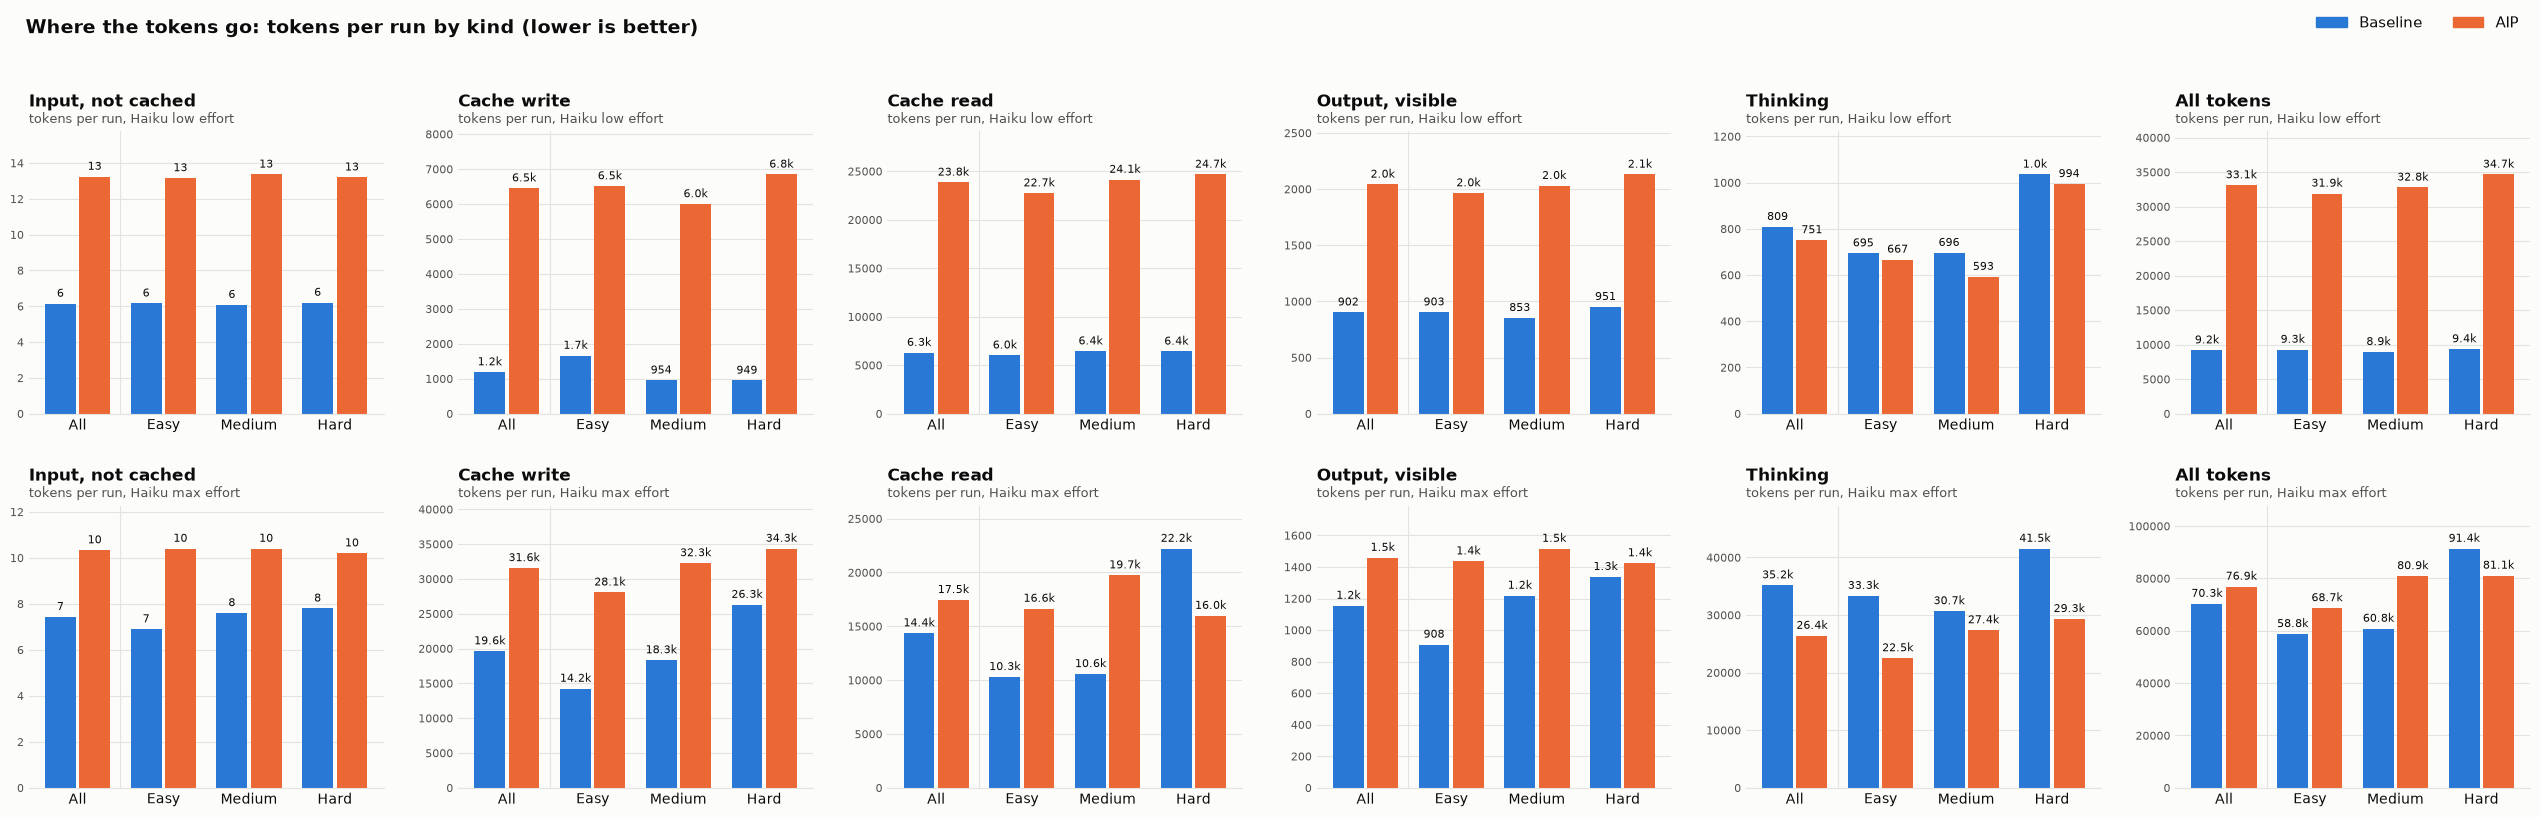

In [9]:
TOKENS = [panel for panel in SPEND if panel[1] == "tokens per run"]
bar_figure(TOKENS, "Where the tokens go: tokens per run by kind (lower is better)", name="tokens.png")
plt.show()

## 2. The two messages

Each run writes a message to the customer and a note to the credit officer. The scripted rubric (in `bench/score.py`) passes a message only if every check holds. The checks are literal, so read the pass rates beside the failures below, not alone: the "outcome first" check looks for particular words in the first sentence and rejects some correct messages, such as "we have decided not to approve".

In [10]:
def rubric_failures():
    """How many runs failed each rubric check, for each arm."""
    counts = {}
    for effort, arm in COLUMNS:
        part = runs[(runs.effort == effort) & (runs.arm == arm)]
        failed = part.message_failures.str.split().explode().dropna()
        column = failed[failed != ""].value_counts().to_dict()
        counts[(f"Haiku {effort}", arm)] = {k: f"{v}/{len(part)}" for k, v in column.items()}
    table = pd.DataFrame(counts).fillna("0")
    table.index = [i.replace(":", " message: ").replace("_", " ") for i in table.index]
    return table.sort_index()

print("Runs failing each rubric check")
rubric_failures()

Runs failing each rubric check


Haiku low         Haiku max      
                                  Baseline     AIP  Baseline   AIP
customer message: outcome first      8/150   6/150      2/60     0
customer message: reasons           26/150  15/150      9/60     0
officer message: outcome first       9/150   4/150      2/60  1/60
officer message: reasons             2/150   2/150      2/60     0
officer message: under 150 words    89/150  48/150      1/60     0

In [11]:
def lengths():
    """Message length in words. The SOP's limit is 150."""
    out = {}
    for effort, arm in COLUMNS:
        part = runs[(runs.effort == effort) & (runs.arm == arm) & (runs.answered == 1)]
        for who, column in (("Customer", "customer_text"), ("Officer", "officer_text")):
            words = part[column].str.split().str.len()
            out[(f"Haiku {effort}", arm, who)] = {"median words": int(words.median()), "longest": int(words.max()),
                                                  "over 150 words": f"{int((words > 150).sum())}/{len(words)}"}
    return pd.DataFrame(out).T

lengths()

median words longest over 150 words
Haiku low Baseline Customer           73     123          0/150
                   Officer           174     349         89/150
          AIP      Customer           82     146          0/150
                   Officer           132     244         48/150
Haiku max Baseline Customer           65     107           0/60
                   Officer           135     157           1/60
          AIP      Customer           65     142           0/60
                   Officer           127     147           0/60

### The messages themselves

One application for each outcome, first repeat, the two arms side by side. Change `SHOW` to read others.

In [12]:
SHOW = {"APP-2006": "approve", "APP-2007": "decline", "APP-2003": "return", "APP-2208": "escalate"}
EFFORT = COLUMNS[0][0]          # which effort to read: "low" or "max"

def side_by_side(application, effort=EFFORT):
    part = runs[(runs.application == application) & (runs.effort == effort) & (runs.answered == 1)]
    first = part.sort_values("repeat").groupby("arm").first()
    cells = ""
    for who, column, check in (("Customer", "customer_text", "customer_message"), ("Officer", "officer_text", "officer_message")):
        cells += "<tr>" + "".join(
            f"<td style='vertical-align:top;text-align:left;width:50%'><b>{who}, {arm}</b> "
            f"({len(first.loc[arm, column].split())} words, rubric {'pass' if first.loc[arm, check] else 'fail'})"
            f"<br>{first.loc[arm, column]}</td>" for arm in first.index) + "</tr>"
    want = EXPECTED[application]
    display(HTML(f"<h4>{application}: expected {want['outcome']} {want['failed_rules'] or want['missing'] or ''}"
                 f" (Haiku {effort})</h4><table>{cells}</table>"))

for application in SHOW:
    side_by_side(application)

"Customer, AIP (109 words, rubric pass)Your application for a $95,000 small-business term loan from Lantern Mutual has been approved. The loan term is 60 months, with a monthly payment of $1,995. We reviewed your business history, your guarantor's credit score, your bankruptcy and tax lien record, your ability to cover the payments, the loan size against your annual revenue, and how the money will be used for the new lumber and sheet goods yard. We also reviewed the two late equipment lease payments in March and April. They happened after your bookkeeper left and the automatic payment lapsed, and both were paid in full by May 2. Your payments have been on time since.","Customer, Baseline (73 words, rubric pass)Your application for a small-business term loan has been approved. The approved amount is $95,000, repayable over 60 months at a quoted monthly payment of $1,995. The loan funds the lumber and sheet goods yard: racking and covered shed ($41,000), a used forklift ($19,000) and opening lumber inventory ($35,000). Your store's current income will cover the repayments, and your explanation of the two late equipment lease payments in March and April was accepted."
"Officer, AIP (144 words, rubric pass)Outcome: approve. $95,000 over 60 months, quoted payment $1,995 a month. All hard rules passed: H1 amount $95,000 (range $10,000 to $250,000); H2 term 60 months (12 to 60); H3 209 months in business (24 or more); H4 guarantor score 705 (660 or higher); H5 no bankruptcy in 7 years, no unpaid tax liens; H6 coverage 3.08 ($12,600 divided by $4,095) (1.25 or more); H7 $95,000 is 12.2% of $780,000 revenue (25% or less). Judgment rules held: J1 eligible purpose (probability 0.98); J2 uses total $95,000: racking and shed $41,000, forklift $19,000, inventory $35,000 (0.99); J3 two late equipment lease payments, March and April, caused by a lapsed automatic payment after the bookkeeper left and the account closed; paid in full by May 2; on time since, per bank statements (0.97); J4 repaid from current store income (0.96); J5 form and story agree (0.87).","Officer, Baseline (184 words, rubric fail)Outcome: approve. Complete, all seven hard rules pass, all five judgment rules hold. Hard rules: H1 amount $95,000 (range $10,000-$250,000). H2 term 60 months (12-60). H3 operating since 2009-06, about 209 months at receipt 2026-11-05 (minimum 24). H4 guarantor score 705 (minimum 660). H5 no bankruptcy in 7 years, no unpaid tax liens. H6 $12,600 / ($2,100 + $1,995) = 3.08 (minimum 1.25). H7 $95,000 / $780,000 = 12.2% (maximum 25%). Judgment rules: J1 holds (high confidence): racking, shed, forklift and inventory are all business uses. J2 holds (high confidence): $41,000 + $19,000 + $35,000 = $95,000 exactly. J3 holds (about 0.8 confidence): two 30+ day late payments on the equipment lease (March and April) are explained by a bookkeeper departure and an autopay lapse when the account was closed in handover; both paid in full by 2 May and autopay on time since, per attached bank statements. J4 holds (high confidence): repayment from the store's current income. J5 holds (high confidence): hardware store, open since June 2009, $95,000 request, no conflicting statements. Note on file. Quoted payment $1,995 used as given; not re-derived."


"Customer, AIP (57 words, rubric pass)We have declined your application for a $50,000 term loan for Tidewater Coffee Roasters LLC. Two requirements were not met. First, your business has operated for 17 months; we require 24 months or more. Second, the guarantor's credit score is 641; we require a score of 660 or higher. Your application was received on 6 November 2026.","Customer, Baseline (72 words, rubric pass)We have declined your application for a $50,000 small-business term loan. Two requirements were not met. First, your business has operated for 17 months as of the date we received your application (since June 2025); we require at least 24 months. Second, the guarantor's credit score is 641; we require a score of 660 or higher. Your application did not go on to the other checks because these requirements were not met."
"Officer, AIP (47 words, rubric fail)Application APP-2007, Tidewater Coffee Roasters LLC, requesting $50,000 over 36 months. Outcome: decline. H3 (Time in business) failed: 17 months in business (operating since 2025-06, received 2026-11-06); threshold 24 months or more. H4 (Credit score) failed: guarantor credit score 641; threshold 660 or higher. No missing items.","Officer, Baseline (109 words, rubric pass)Decline, APP-2007 (Tidewater Coffee Roasters LLC, $50,000 over 36 months, quoted $1,602/month). Failed hard rules: H3 Time in business: operating since 2025-06, received 2026-11-06, which is 17 months against a 24-month minimum. H4 Credit score: guarantor score 641 against a 660 minimum. Other hard rules pass: H1 amount $50,000 (range $10,000 to $250,000); H2 term 36 months (12 to 60); H5 no bankruptcy and no unpaid tax liens; H6 coverage $6,900 / ($400 + $1,602) = 3.45 against 1.25; H7 size $50,000 / $290,000 = 17.2% against 25%. The application is complete. Judgment rules J1 to J5 were not assessed because the application fails hard rules. File as declined."


"Customer, AIP (67 words, rubric fail)We are returning your application for Juniper Dental Lab LLC (APP-2003) without a decision, because a required document is missing. Please send the business bank statements for the last six months. We understand your bank's online system changed and you could not download them, so send them when you can. Once they arrive, we will assess your application. Nothing else on the form is holding it up.","Customer, Baseline (60 words, rubric fail)We are returning your application for a $40,000 small-business term loan because it is incomplete. The required business bank statements for the last six months are missing from the documents attached. Please send those statements when you have them. Once they arrive, your application will be assessed. Your other documents, the business tax returns and the guarantor's ID, were received."
"Officer, AIP (127 words, rubric fail)Outcome: return. No hard rules failed and no judgment rules were assessed. The application is missing one required document: business bank statements for the last six months (absent document). Section 7 says the applicant's bank changed its online system last month, the statements could not be downloaded, and they will be sent later. Figures on file: amount requested $40,000, term 36 months, quoted payment $1,281 per month; guarantor credit score 741; no bankruptcy in the last 7 years; no unpaid tax liens; 0 payments 30 or more days late in the last 12 months. Attached: business tax returns for the last two years and the guarantor's government-issued ID. Business: Juniper Dental Lab LLC, operating since 2015-02, annual revenue $355,000, average monthly net income $7,800, no existing debt.","Officer, Baseline (75 words, rubric pass)APP-2003 is returned as incomplete. The only missing item is the required document ""Business bank statements, last six months""; the applicant states the bank's online system prevented download and that statements will follow. All fields in sections 1 to 3 have values, and the tax returns and guarantor ID are attached. No hard or judgment rules were applied, as the policy requires. On receipt of the statements, the application should be re-run from the start."


"Customer, AIP (93 words, rubric pass)Your application for a $160,000 term loan over 60 months, with a quoted monthly payment of $3,360, will be reviewed by a credit officer. The officer will look at one thing: whether the two late payments in the last 12 months, on your steel supplier account in May and August, have an explanation that names a specific cause and shows that cause is over. The cause you describe is one general contractor paying you around ninety days after invoice, against your thirty-day terms, and you have said this will continue through next summer.","Customer, Baseline (98 words, rubric pass)Your application for a $160,000 small-business term loan has been referred to a credit officer for review. The officer will look at the two late supplier payments in May and August and the cause you gave, which was one customer paying on ninety-day terms. The officer will also look at whether that cause has been resolved, since you said it has not yet, and at how the loan would be repaid from the shop's current income. Your figures for time in business, credit score, coverage and the size of the request have all been checked against our criteria."
"Officer, AIP (157 words, rubric fail)Outcome: escalate. Rule J3 (adverse items are explained) does not hold; probability it holds: 0.03. Application APP-2208, Northfork Steel Fabrication Inc, requests $160,000 over 60 months, quoted payment $3,360. Adverse items: two payments 30 or more days late in the last 12 months (section 3), on the steel supplier trade account, in May and August. Section 7 gives the cause: one general contractor, about a third of work, paying around 90 days against 30-day terms, so the steel bill waits when their large invoices are outstanding. The applicant says the cause is not behind them: two more jobs with this contractor run through next summer, the same squeeze is expected at least once more, and a request for better terms has had no answer. Rules J1 (0.99), J2 (0.99), J4 (0.98) and J5 (0.89) held. Question to settle: does the explanation name a specific cause that is over, given the applicant's own statement that it is not?","Officer, Baseline (251 words, rubric fail)Outcome: escalate. All hard rules pass and the application is complete. H1 $160,000 (range 10,000 to 250,000); H2 60 months (12 to 60); H3 operating since 2009-08, about 207 months (24 or more); H4 credit score 682 (660 or more); H5 no bankruptcy, no unpaid tax liens; H6 coverage 23,500 / (6,400 + 3,360) = 2.41 (1.25 or more); H7 160,000 / 1,880,000 = 8.5% (25% or less). Judgment rules: J1 holds (high confidence): CNC plasma table, compressor/air dryer and software/training are all business uses. J2 holds (high confidence): 118,000 + 22,000 + 20,000 = 160,000, exact match. J4 holds (high confidence): applicant states repayment comes from current shop income and does not rely on the table's efficiency gains. J5 holds (high confidence): steel fabrication, operating since 2009, 14 shop staff and 4 field crew, nothing contradicts section 1 to 3 fields. J3 does not hold (high confidence): section 3 declares 2 payments 30 or more days late in the last 12 months. The section 7 explanation names a specific cause (one general contractor paying at about 90 days against 30-day terms), but the applicant states it is not behind them, expects the same squeeze again, and has two more jobs with that customer through next summer. The adverse item is not shown to be over. Question for the officer: is a named, recurring customer payment delay that the applicant expects to continue acceptable as an explained adverse item, or does J3 fail so the loan cannot proceed on these terms?"


## 3. Tokens and cost

Claude Code reports four kinds of token for a run, and they are billed at different rates:

- **Input, not cached:** new text sent to the model at the full input rate. Almost nothing here, because Claude Code caches what it sends.
- **Cache write:** new context written to the cache (the files read, the tool replies), billed above the input rate.
- **Cache read:** context already in the cache, re-read on each later turn, billed at a fraction of the input rate.
- **Output:** what the model writes, at the output rate. Thinking is output. It is shown apart here as **thinking** and **output, visible** (the tool calls, the answer and the messages).

The AIP columns cover the agent only. The decision model's calls are not Claude tokens and are not in these numbers.

In [13]:
runs["tokens_visible"] = runs.tokens_output - runs.tokens_thinking
TYPES = {"tokens_input": "Input, not cached", "tokens_cache_write": "Cache write", "tokens_cache_read": "Cache read",
         "tokens_visible": "Output, visible", "tokens_thinking": "Thinking"}

def direction(base, other, fmt):
    """Up or down, by what factor, and by how much."""
    if base == other:
        return "same"
    sign = "+" if other > base else "-"
    factor = f" {other / base:.2f}x" if base else ""
    return f"{'up' if other > base else 'down'}{factor}  ({sign}{fmt(abs(other - base))})"

def compare(values, label, fmt):
    """Baseline and AIP side by side for each effort, with the direction of the change."""
    frames = []
    for effort in dict.fromkeys(e for e, _ in COLUMNS):
        base, aip = values.get((effort, "Baseline")), values.get((effort, "AIP"))
        if base is None or aip is None:
            continue
        frame = pd.DataFrame({"Baseline": base.map(fmt), "AIP": aip.map(fmt),
                              "AIP against baseline": [direction(b, a, fmt) for b, a in zip(base, aip)]})
        frame.columns = pd.MultiIndex.from_product([[f"Haiku {effort}: {label}"], frame.columns])
        frames.append(frame)
    return pd.concat(frames, axis=1)

mean_tokens = {key: part[list(TYPES)].mean().rename(TYPES) for key, part in runs.groupby(["effort", "arm"])}
for key in mean_tokens:
    mean_tokens[key]["All tokens"] = mean_tokens[key].sum()
compare(mean_tokens, "tokens per run", lambda v: f"{v:,.0f}")

Haiku low: tokens per run                               \
                                   Baseline     AIP AIP against baseline   
Input, not cached                         6      13       up 2.15x  (+7)   
Cache write                           1,188   6,452   up 5.43x  (+5,264)   
Cache read                            6,287  23,850  up 3.79x  (+17,563)   
Output, visible                         902   2,041   up 2.26x  (+1,138)   
Thinking                                809     751    down 0.93x  (-57)   
All tokens                            9,192  33,107  up 3.60x  (+23,915)   

                  Haiku max: tokens per run                                
                                   Baseline     AIP  AIP against baseline  
Input, not cached                         7      10        up 1.39x  (+3)  
Cache write                          19,624  31,563   up 1.61x  (+11,939)  
Cache read                           14,363  17,458    up 1.22x  (+3,095)  
Output, visible                       1,155   1,459      up 1.26x  (+304)  
Thinking                             35,186  26,413  down 0.75x  (-8,774)  
All tokens                           70,336  76,903    up 1.09x  (+6,567)

### What each kind of token costs

Claude Code reports one cost per run, not a cost per kind of token. The prices below are recovered from the runs themselves: a run's cost is its tokens times the price of each kind, so fitting cost against the four token counts across all runs gives the four prices. The last line says how closely the fitted prices reproduce the reported costs; a close fit means the prices are the ones Claude Code used. Thinking is priced as output.

In [14]:
import numpy as np

def fit_prices(part):
    """Dollars per token for each billed kind, by least squares on the runs' reported costs."""
    billed = ["tokens_input", "tokens_cache_write", "tokens_cache_read", "tokens_output"]
    part = part[part.answered == 1]
    prices, *_ = np.linalg.lstsq(part[billed].to_numpy(float), part.cost_exact.to_numpy(float), rcond=None)
    error = np.abs(part[billed].to_numpy(float) @ prices - part.cost_exact).max()
    return dict(zip(billed, prices)), error

PRICE, fit_error = fit_prices(runs)
PRICE["tokens_visible"] = PRICE["tokens_thinking"] = PRICE["tokens_output"]

price_table = pd.DataFrame({"$ per 1M tokens": {TYPES[k]: f"${PRICE[k] * 1e6:,.3f}" for k in TYPES}})
display(price_table)
print(f"Largest gap between a run's reported cost and its cost at these prices: ${fit_error:.6f}")
print("Input, not cached, is only a handful of tokens per run, so its fitted price is the least certain of the five.")

,$ per 1M tokens
"Input, not cached",$0.100
Cache write,$0.125
Cache read,$0.010
"Output, visible",$0.500
Thinking,$0.500


Largest gap between a run's reported cost and its cost at these prices: $0.000000
Input, not cached, is only a handful of tokens per run, so its fitted price is the least certain of the five.


### Cost per run, by kind of token

The same comparison in dollars: each kind's tokens times its price. This is where the direction of the change matters, because a kind can grow a lot in tokens and little in cost (cache reads) or the reverse (output and thinking).

In [15]:
def cost_by_type(part):
    cost = pd.Series({TYPES[k]: part[k].mean() * PRICE[k] for k in TYPES})
    cost["All tokens"] = cost.sum()
    return cost

mean_cost = {key: cost_by_type(part) for key, part in runs.groupby(["effort", "arm"])}
compare(mean_cost, "cost per run", lambda v: f"${v:.5f}")

Haiku low: cost per run                                     \
                                 Baseline       AIP     AIP against baseline   
Input, not cached                $0.00000  $0.00000    up 2.15x  (+$0.00000)   
Cache write                      $0.00015  $0.00081    up 5.43x  (+$0.00066)   
Cache read                       $0.00006  $0.00024    up 3.79x  (+$0.00018)   
Output, visible                  $0.00045  $0.00102    up 2.26x  (+$0.00057)   
Thinking                         $0.00040  $0.00038  down 0.93x  (-$0.00003)   
All tokens                       $0.00107  $0.00244    up 2.29x  (+$0.00137)   

                  Haiku max: cost per run                                     
                                 Baseline       AIP     AIP against baseline  
Input, not cached                $0.00000  $0.00000    up 1.39x  (+$0.00000)  
Cache write                      $0.00245  $0.00395    up 1.61x  (+$0.00149)  
Cache read                       $0.00014  $0.00017    up 1.22x  (+$0.00003)  
Output, visible                  $0.00058  $0.00073    up 1.26x  (+$0.00015)  
Thinking                         $0.01759  $0.01321  down 0.75x  (-$0.00439)  
All tokens                       $0.02077  $0.01806  down 0.87x  (-$0.00271)

In [16]:
def shares():
    """Each kind's share of the run's tokens and of its cost."""
    out = {}
    for effort, arm in COLUMNS:
        tokens, cost = mean_tokens[(effort, arm)].drop("All tokens"), mean_cost[(effort, arm)].drop("All tokens")
        out[(f"Haiku {effort}", arm, "share of tokens")] = (tokens / tokens.sum()).map("{:.0%}".format)
        out[(f"Haiku {effort}", arm, "share of cost")] = (cost / cost.sum()).map("{:.0%}".format)
    return pd.DataFrame(out)

shares()

Haiku low                                              \
                         Baseline                           AIP                 
                  share of tokens share of cost share of tokens share of cost   
Input, not cached              0%            0%              0%            0%   
Cache write                   13%           14%             19%           33%   
Cache read                    68%            6%             72%           10%   
Output, visible               10%           42%              6%           42%   
Thinking                       9%           38%              2%           15%   

                        Haiku max                                              
                         Baseline                           AIP                
                  share of tokens share of cost share of tokens share of cost  
Input, not cached              0%            0%              0%            0%  
Cache write                   28%           12%             41%           22%  
Cache read                    20%            1%             23%            1%  
Output, visible                2%            3%              2%            4%  
Thinking                      50%           85%             34%           73%

### Average cost per million tokens

What a run pays, on average, for a million tokens of everything it uses. The arms differ because their mix differs: a run made mostly of cache reads is cheap per token, a run made mostly of thinking is expensive per token.

In [17]:
def blended():
    out = {}
    for effort, arm in COLUMNS:
        part = runs[(runs.effort == effort) & (runs.arm == arm)]
        out[(f"Haiku {effort}", arm)] = {
            "Tokens per run": f"{part.tokens_total.mean():,.0f}",
            "Cost per run": f"${part.cost_exact.mean():.5f}",
            "Average $ per 1M tokens": f"${part.cost_exact.sum() / part.tokens_total.sum() * 1e6:.3f}",
            "Cost per correct decision": f"${part.cost_exact.sum() / max(part.decided.sum(), 1):.5f}",
        }
    return pd.DataFrame(out)

blended()

Haiku low           Haiku max          
                           Baseline       AIP  Baseline       AIP
Tokens per run                9,192    33,107    70,336    76,903
Cost per run               $0.00107  $0.00244  $0.02077  $0.01806
Average $ per 1M tokens      $0.116    $0.074    $0.295    $0.235
Cost per correct decision  $0.00117  $0.00244  $0.02225  $0.01806

## 4. What more thinking changes

The same arm at low and at max effort, so the only thing that differs is how much the model thinks. "Change" is max against low. The first table is the baseline over all thirty applications and then tier by tier; the second is the same for AIP.

Two things to keep in mind when reading it. The low runs have five repeats of each application and the max runs have two, so the max correctness figures rest on fewer runs. And the max runs went sixteen at a time where the low runs went eight, so compare seconds between efforts with care.

In [18]:
def thinking_effect(arm):
    return pd.concat({scope: contrast(pick("low", arm, tier), pick("max", arm, tier), ["Low", "Max"])
                      for scope, tier in [("All", None)] + [(t, t) for t in TIERS]}, axis=1)

display(Markdown("**Baseline: low effort against max**"))
display(thinking_effect("Baseline"))
display(Markdown("**AIP: low effort against max**"))
display(thinking_effect("AIP"))

**Baseline: low effort against max**

All                           \
                                    Low           Max     Change   
Outcome correct           141/150 (94%)   58/60 (97%)  +3 points   
Rules list correct        137/150 (91%)   56/60 (93%)  +2 points   
Missing list correct     150/150 (100%)  60/60 (100%)       same   
Thinking tokens per run             809        35,186   up 43.5x   
All tokens per run                9,192        70,336    up 7.7x   
Cost per run                    $0.0011       $0.0208   up 19.5x   
Seconds per run                     8.1         142.6   up 17.7x   

                                 easy                                  medium  \
                                  Low           Max      Change           Low   
Outcome correct           48/50 (96%)   18/20 (90%)   -6 points  50/50 (100%)   
Rules list correct        46/50 (92%)   16/20 (80%)  -12 points  50/50 (100%)   
Missing list correct     50/50 (100%)  20/20 (100%)        same  50/50 (100%)   
Thinking tokens per run           695        33,340    up 48.0x           696   
All tokens per run              9,277        58,799     up 6.3x         8,944   
Cost per run                  $0.0011       $0.0190    up 17.8x       $0.0010   
Seconds per run                   7.5         134.9    up 17.9x           7.2   

                                                         hard                \
                                  Max    Change           Low           Max   
Outcome correct          20/20 (100%)      same   43/50 (86%)  20/20 (100%)   
Rules list correct       20/20 (100%)      same   41/50 (82%)  20/20 (100%)   
Missing list correct     20/20 (100%)      same  50/50 (100%)  20/20 (100%)   
Thinking tokens per run        30,688  up 44.1x         1,035        41,532   
All tokens per run             60,819   up 6.8x         9,354        91,389   
Cost per run                  $0.0184  up 19.1x       $0.0012       $0.0249   
Seconds per run                 124.1  up 17.2x           9.4         168.9   

                                     
                             Change  
Outcome correct          +14 points  
Rules list correct       +18 points  
Missing list correct           same  
Thinking tokens per run    up 40.1x  
All tokens per run          up 9.8x  
Cost per run               up 21.2x  
Seconds per run            up 18.0x

**AIP: low effort against max**

All                                  easy  \
                                    Low           Max    Change           Low   
Outcome correct          150/150 (100%)  60/60 (100%)      same  50/50 (100%)   
Rules list correct       150/150 (100%)  60/60 (100%)      same  50/50 (100%)   
Missing list correct     150/150 (100%)  60/60 (100%)      same  50/50 (100%)   
Thinking tokens per run             751        26,413  up 35.1x           667   
All tokens per run               33,107        76,903   up 2.3x        31,897   
Cost per run                    $0.0024       $0.0181   up 7.4x       $0.0024   
Seconds per run                    13.7         106.3   up 7.8x          12.4   

                                                       medium                \
                                  Max    Change           Low           Max   
Outcome correct          20/20 (100%)      same  50/50 (100%)  20/20 (100%)   
Rules list correct       20/20 (100%)      same  50/50 (100%)  20/20 (100%)   
Missing list correct     20/20 (100%)      same  50/50 (100%)  20/20 (100%)   
Thinking tokens per run        22,523  up 33.8x           593        27,382   
All tokens per run             68,683   up 2.2x        32,772        80,927   
Cost per run                  $0.0157   up 6.6x       $0.0023       $0.0187   
Seconds per run                  92.2   up 7.5x          13.9         109.1   

                                           hard                          
                           Change           Low           Max    Change  
Outcome correct              same  50/50 (100%)  20/20 (100%)      same  
Rules list correct           same  50/50 (100%)  20/20 (100%)      same  
Missing list correct         same  50/50 (100%)  20/20 (100%)      same  
Thinking tokens per run  up 46.2x           994        29,333  up 29.5x  
All tokens per run        up 2.5x        34,653        81,099   up 2.3x  
Cost per run              up 8.1x       $0.0027       $0.0198   up 7.4x  
Seconds per run           up 7.8x          14.7         117.6   up 8.0x

In [19]:
def overall():
    """One table: every arm and effort, the headline figures."""
    out = {}
    for arm in ("Baseline", "AIP"):
        for effort in dict.fromkeys(e for e, a in COLUMNS if a == arm):
            f = facts(pick(effort, arm))
            out[(arm, f"Haiku {effort}")] = {k: shown(*f[k]) for k in f}
    return pd.DataFrame(out)

overall()

Baseline                           AIP  \
                              Haiku low     Haiku max       Haiku low   
Outcome correct           141/150 (94%)   58/60 (97%)  150/150 (100%)   
Rules list correct        137/150 (91%)   56/60 (93%)  150/150 (100%)   
Missing list correct     150/150 (100%)  60/60 (100%)  150/150 (100%)   
Thinking tokens per run             809        35,186             751   
All tokens per run                9,192        70,336          33,107   
Cost per run                    $0.0011       $0.0208         $0.0024   
Seconds per run                     8.1         142.6            13.7   

                                       
                            Haiku max  
Outcome correct          60/60 (100%)  
Rules list correct       60/60 (100%)  
Missing list correct     60/60 (100%)  
Thinking tokens per run        26,413  
All tokens per run             76,903  
Cost per run                  $0.0181  
Seconds per run                 106.3